Passage à elapid afin de réaliser ce projet.
On garde nos data, elles ont déjà été subsample, plus besoin de conversion entre tif à asc,

In [2]:
import pandas as pd
import geopandas as gpd
import rasterio
import elapid as ela
from sklearn import metrics
from pathlib import Path
import matplotlib.pyplot as plt
from elapid import MaxentModel
from rasterio.plot import show
import numpy as np

Chemin d'accès vers les fichiers Bioclimatic du présent et de 2080-2100 ainsi que du dossier des occurences de nos 3 espèces (Koala, Eucalyptus & Petauroides).

In [3]:
env_present_dir = Path(r"C:\Users\THEO\Documents\Projet\PROJET_kaliptus\wc_biovar_present_tif")
env_future_dir = Path(r"C:\Users\THEO\Documents\Projet\PROJET_kaliptus\wc_biovar2080_tif")

occ_dir = Path(r"C:\Users\THEO\Documents\Projet\PROJET_kaliptus\occurences")

# Chargement du fichier d'occurrence pour l'espèce "koala"
species_name = "koala"
occ_file = occ_dir / f"{species_name}.csv"

print("Fichier d'occurrence :", occ_file)

Fichier d'occurrence : C:\Users\THEO\Documents\Projet\PROJET_kaliptus\occurences\koala.csv


Renommage des colonnes, au lieu d'avoir decimalLongitude & decimalLatitude, on passe à longitude & latitude

In [4]:
# 1. Koala
df = pd.read_csv(r"C:\Users\THEO\Documents\Projet\PROJET_kaliptus\occurences\koala.csv")
df = df.rename(columns={"decimalLongitude": "longitude", "decimalLatitude": "latitude"})

# 2. Eucalyptus
df2 = pd.read_csv(r"C:\Users\THEO\Documents\Projet\PROJET_kaliptus\occurences\eucalyptus.csv")
df2 = df2.rename(columns={"decimalLongitude": "longitude", "decimalLatitude": "latitude"})

# 3. Pétaurides
df3 = pd.read_csv(r"C:\Users\THEO\Documents\Projet\PROJET_kaliptus\occurences\petauroides.csv")
df3 = df3.rename(columns={"decimalLongitude": "longitude", "decimalLatitude": "latitude"})




Choix des variables Bioclimatic utilisé : Bio 1, 5, 6, 12, 14, 15.


In [5]:
# Liste fichiers .tif (bio1, bio5, bio6, bio12, bio14, bio15)
raster_files = sorted(list(env_present_dir.glob("*.tif")))
print("Variables environnementales détectées :", [f.name for f in raster_files])

future_raster_files = sorted(list(env_future_dir.glob("*.tif")))
print("Variables environnementales futures détectées :", [f.name for f in future_raster_files])

Variables environnementales détectées : ['wc2.1_10m_bio_1.tif', 'wc2.1_10m_bio_12.tif', 'wc2.1_10m_bio_14.tif', 'wc2.1_10m_bio_15.tif', 'wc2.1_10m_bio_5.tif', 'wc2.1_10m_bio_6.tif']
Variables environnementales futures détectées : ['wc2.1_10m_bio_1.tif', 'wc2.1_10m_bio_12.tif', 'wc2.1_10m_bio_14.tif', 'wc2.1_10m_bio_15.tif', 'wc2.1_10m_bio_5.tif', 'wc2.1_10m_bio_6.tif']


In [6]:
# Liste de vos espèces à traiter
species_list = ["koala", "eucalyptus", "petauroides"] # Adaptez les noms selon vos fichiers d'occurrences

for sp_name in species_list:
    print(f"\n--- Traitement en cours pour : {sp_name} ---")
    
    # 1. Charger les occurrences de l'espèce (adaptez le nom du fichier si besoin)
    csv_path = occ_dir / f"{sp_name}.csv"
    df_occ = pd.read_csv(csv_path)
    print(f"Nombre d'occurrences pour {sp_name} : {len(df_occ)}")

    df_occ = df_occ.rename(columns={"decimalLongitude": "longitude", "decimalLatitude": "latitude"})
    
    # 2. Préparation géospatiale & Background (déjà fait pour Koala, répété pour les autres)
    geometry = ela.xy_to_geoseries(df_occ['longitude'], df_occ['latitude'])
    presence_gdf = gpd.GeoDataFrame(df_occ, geometry=geometry, crs="EPSG:4326")
    
    background_gdf = ela.sample_raster(raster_files[0], count=10000)
    merged_data = ela.stack_geodataframes(presence_gdf, background_gdf, add_class_label=True)
    
    # 3. Annotation
    annotated_data = ela.annotate(merged_data, raster_files, drop_na=True, quiet=True)
    
    # # Correction des noms de colonnes b1-b6 si nécessaire
    # col_mapping = {f"b{i+1}": f.stem for i, f in enumerate(raster_files)}
    # annotated_data = annotated_data.rename(columns=col_mapping)
    
    # feature_cols = [f.stem for f in raster_files]

    feature_cols = ['b1', 'b2', 'b3', 'b4', 'b5', 'b6'] 
    x = annotated_data[feature_cols]
    y = annotated_data['class']
    
    # 4. Entraînement
    model = ela.MaxentModel(beta_multiplier=1.0, transform='logistic')
    model.fit(x, y)

    ypred = model.predict(x)
    train_auc = metrics.roc_auc_score(y, ypred)
    print(f"✅ Modèle entraîné avec succès ! Score AUC d'entraînement : {train_auc:.4f}")
    
    # 5. Projection 2080 spécifique
    output_pred_tif = Path(r"C:\Users\THEO\Documents\Projet\PROJET_kaliptus") / f"prediction_2080_{sp_name.lower()}.tif"
    ela.apply_model_to_rasters(model, future_raster_files, output_pred_tif)
    
    print(f"✅ Fichier généré : {output_pred_tif.name}")


--- Traitement en cours pour : koala ---
Nombre d'occurrences pour koala : 876
✅ Modèle entraîné avec succès ! Score AUC d'entraînement : 0.9920


Window:   0%|                              | 0/1080 [00:00<?, ?it/s]

✅ Fichier généré : prediction_2080_koala.tif

--- Traitement en cours pour : eucalyptus ---
Nombre d'occurrences pour eucalyptus : 1496
✅ Modèle entraîné avec succès ! Score AUC d'entraînement : 0.9896


Window:   0%|                              | 0/1080 [00:00<?, ?it/s]

✅ Fichier généré : prediction_2080_eucalyptus.tif

--- Traitement en cours pour : petauroides ---
Nombre d'occurrences pour petauroides : 1200
✅ Modèle entraîné avec succès ! Score AUC d'entraînement : 0.9941


Window:   0%|                              | 0/1080 [00:00<?, ?it/s]

✅ Fichier généré : prediction_2080_petauroides.tif


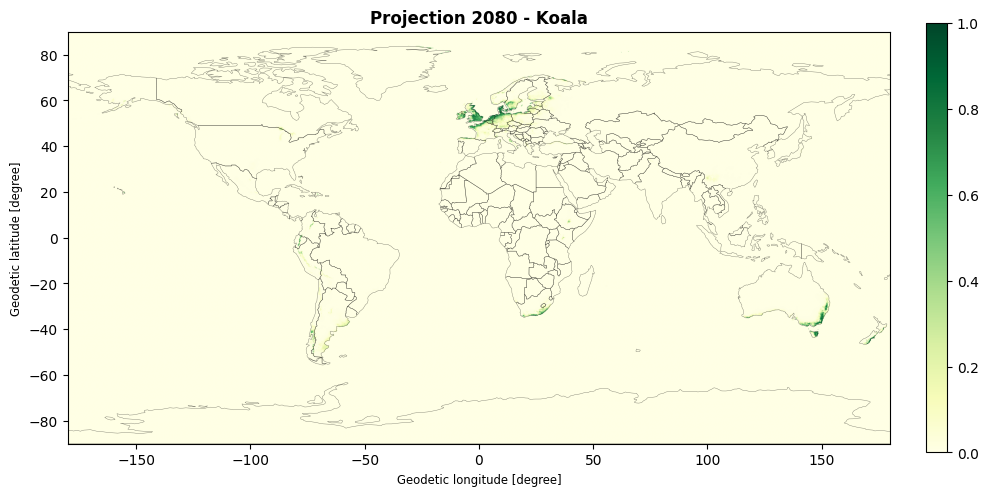

In [7]:
path = Path(r"C:\Users\THEO\Documents\Projet\PROJET_kaliptus\prediction_2080_koala.tif")
world = gpd.read_file("https://d2ad6b4ur7yvpq.cloudfront.net/naturalearth-3.3.0/ne_110m_admin_0_countries.geojson")

fig, ax = plt.subplots(figsize=(10, 5))
with rasterio.open(path) as src:
    img = src.read(1)
    im = ax.imshow(img, cmap='YlGn', vmin=0, vmax=1, extent=[src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top])

world.plot(ax=ax, facecolor='none', edgecolor='black', linewidth=0.3, alpha=0.5)
ax.set_title("Projection 2080 - Koala", fontsize=12, fontweight='bold')
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.04)
plt.tight_layout()
plt.show()

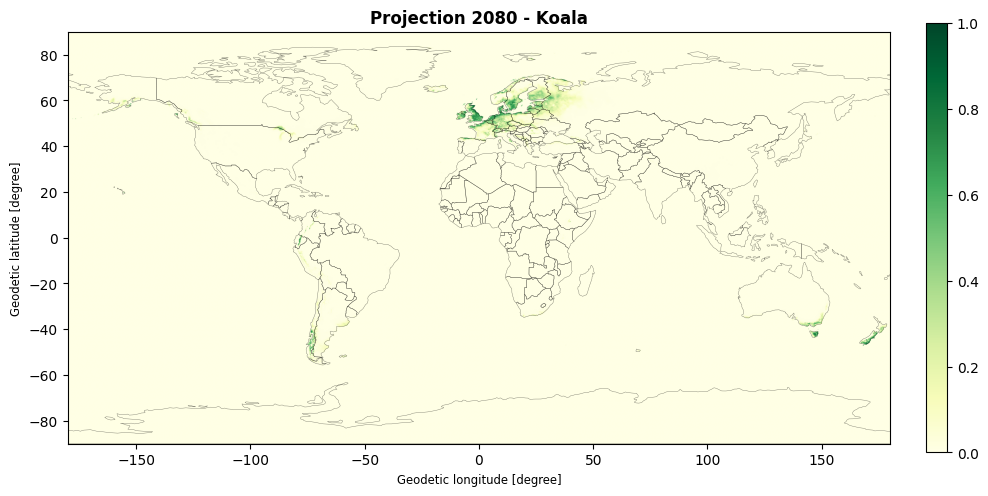

In [8]:
path = Path(r"C:\Users\THEO\Documents\Projet\PROJET_kaliptus\prediction_2080_eucalyptus.tif")
world = gpd.read_file("https://d2ad6b4ur7yvpq.cloudfront.net/naturalearth-3.3.0/ne_110m_admin_0_countries.geojson")

fig, ax = plt.subplots(figsize=(10, 5))
with rasterio.open(path) as src:
    img = src.read(1)
    im = ax.imshow(img, cmap='YlGn', vmin=0, vmax=1, extent=[src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top])

world.plot(ax=ax, facecolor='none', edgecolor='black', linewidth=0.3, alpha=0.5)
ax.set_title("Projection 2080 - Koala", fontsize=12, fontweight='bold')
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.04)
plt.tight_layout()
plt.show()

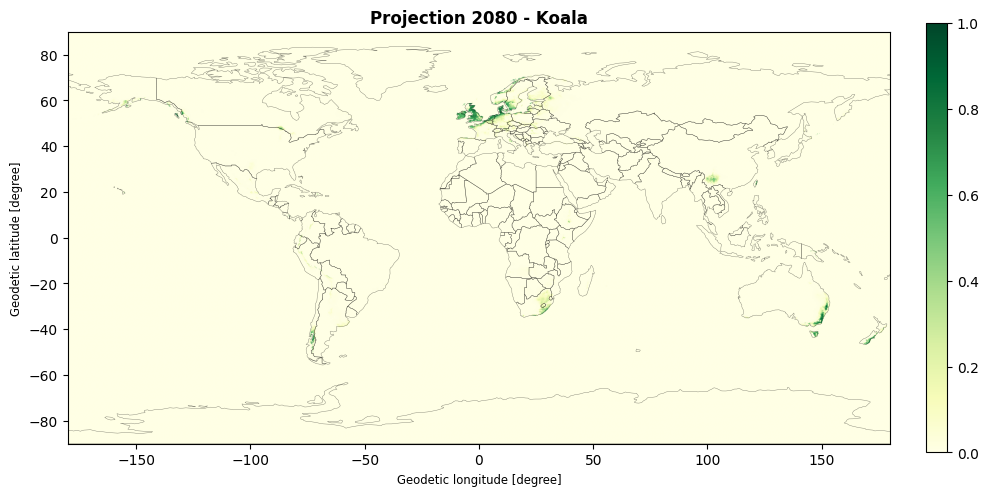

In [9]:
path = Path(r"C:\Users\THEO\Documents\Projet\PROJET_kaliptus\prediction_2080_petauroides.tif")
world = gpd.read_file("https://d2ad6b4ur7yvpq.cloudfront.net/naturalearth-3.3.0/ne_110m_admin_0_countries.geojson")

fig, ax = plt.subplots(figsize=(10, 5))
with rasterio.open(path) as src:
    img = src.read(1)
    im = ax.imshow(img, cmap='YlGn', vmin=0, vmax=1, extent=[src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top])

world.plot(ax=ax, facecolor='none', edgecolor='black', linewidth=0.3, alpha=0.5)
ax.set_title("Projection 2080 - Koala", fontsize=12, fontweight='bold')
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.04)
plt.tight_layout()
plt.show()

In [16]:
output_dir = Path(r"C:\Users\THEO\Documents\Projet\PROJET_kaliptus")
path_koala = output_dir / "prediction_2080_koala.tif"
path_euc = output_dir / "prediction_2080_eucalyptus.tif"
path_peta = output_dir / "prediction_2080_petauroides.tif"
output_refuge = output_dir / "refuges_climatiques_mondial_2080.tif"

# 1. Ouvrir les 3 rasters de 2080
with rasterio.open(path_koala) as src_k, \
     rasterio.open(path_euc) as src_e, \
     rasterio.open(path_peta) as src_p:
     
     koala_arr = src_k.read(1)
     euc_arr = src_e.read(1)
     peta_arr = src_p.read(1)


     # Récupérer les métadonnées (pour sauvegarder le résultat en TIF à la fin)
     profile = src_k.profile
     nodata_val = src_k.nodatavals[0]

# 2. Gérer proprement les masques de données valides (exclure le NoData ou les NaN)
if nodata_val is not None:
    valid_koala = (koala_arr != nodata_val) & (~np.isnan(koala_arr))
    valid_euc = (euc_arr != nodata_val) & (~np.isnan(euc_arr))
    valid_peta = (peta_arr != nodata_val) & (~np.isnan(peta_arr))
else:
    valid_koala = ~np.isnan(koala_arr)
    valid_euc = ~np.isnan(euc_arr)
    valid_peta = ~np.isnan(peta_arr)

global_valid = valid_koala & valid_euc & valid_peta

threshold = 0.5
koala_bin = ((koala_arr >= threshold) & valid_koala).astype(int)
euc_bin = ((euc_arr >= threshold) & valid_euc).astype(int)
peta_bin = ((peta_arr >= threshold) & valid_peta).astype(int)

# 2. Intersection continue (multiplication des probabilités)
refuge_grid = koala_arr * euc_arr * peta_arr

nodata_output = -9999
refuge_grid = np.where(global_valid, refuge_grid, nodata_output)

# 3. Sauvegarder le fichier mondial combiné
profile.update(dtype=rasterio.float32, count=1)
with rasterio.open(output_refuge, 'w', **profile) as dst:
    dst.write(refuge_grid.astype(rasterio.float32), 1)


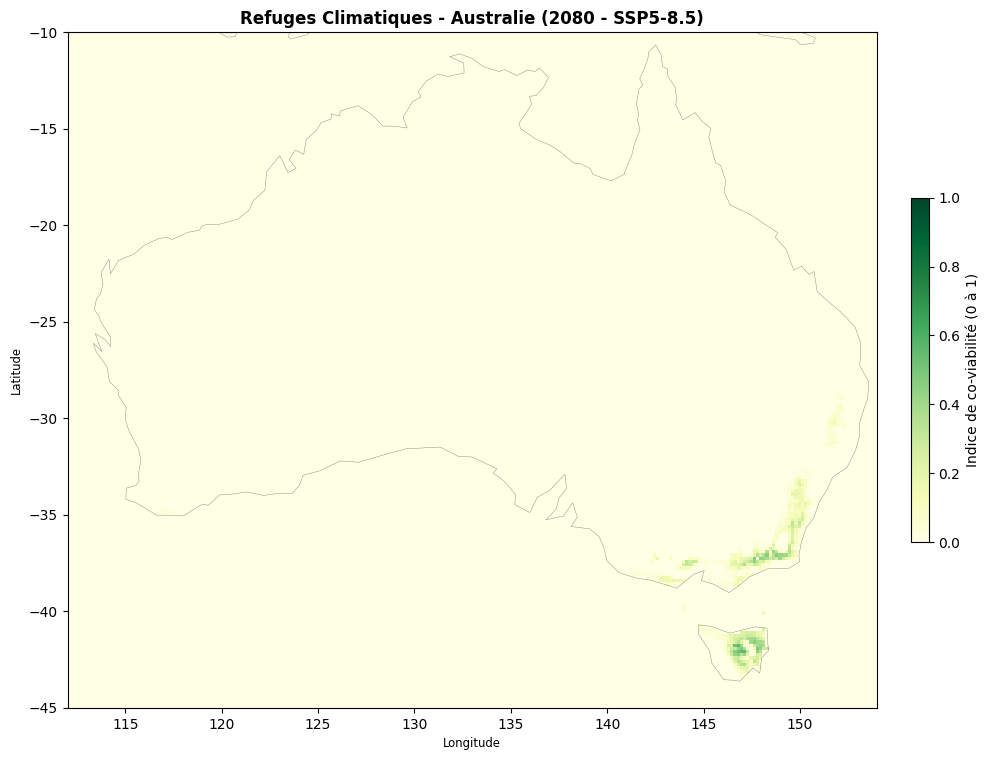

In [19]:
import matplotlib.pyplot as plt
import rasterio
import geopandas as gpd

# 1. Charger le raster mondial combiné
raster_path = r"C:\Users\THEO\Documents\Projet\PROJET_kaliptus\refuges_climatiques_mondial_2080.tif"

# 2. Charger les frontières mondiales pour les superposer
url_world = "https://d2ad6b4ur7yvpq.cloudfront.net/naturalearth-3.3.0/ne_110m_admin_0_countries.geojson"
world = gpd.read_file(url_world)

# 3. Configurer la figure
fig, ax = plt.subplots(figsize=(10, 8))

with rasterio.open(raster_path) as src:
    img_array = src.read(1)
    im = ax.imshow(
        img_array, 
        cmap='YlGn', 
        vmin=0, vmax=1, 
        extent=[src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]
    )

# Superposer les frontières mondiales en filigrane
world.plot(ax=ax, facecolor='none', edgecolor='black', linewidth=0.3, alpha=0.5)

# --- 4. ZOOM SUR L'AUSTRALIE ---
ax.set_xlim([112, 154])  # Longitudes min et max de l'Australie
ax.set_ylim([-45, -10])  # Latitudes min et max de l'Australie (Sud = négatif)

# Esthétique
ax.set_title("Refuges Climatiques - Australie (2080 - SSP5-8.5)", fontsize=12, fontweight='bold')
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

cbar = fig.colorbar(im, ax=ax, fraction=0.02, pad=0.04)
cbar.set_label("Indice de co-viabilité (0 à 1)", fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:
# 1. Charger le raster mondial combiné
raster_path = r"C:\Users\THEO\Documents\Projet\PROJET_kaliptus\refuges_climatiques_mondial_2080.tif"

# 2. Charger les frontières mondiales pour les superposer
url_world = "https://d2ad6b4ur7yvpq.cloudfront.net/naturalearth-3.3.0/ne_110m_admin_0_countries.geojson"
world = gpd.read_file(url_world)

# 3. Configurer la figure
fig, ax = plt.subplots(figsize=(12, 6))

with rasterio.open(raster_path) as src:
    img_array = src.read(1)
    im = ax.imshow(
        img_array, 
        cmap='YlGn', 
        vmin=0, vmax=1, 
        extent=[src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]
    )

# Superposer les frontières mondiales en filigrane
world.plot(ax=ax, facecolor='none', edgecolor='black', linewidth=0.3, alpha=0.5)

# Esthétique
ax.set_title("Refuges Climatiques Mondiaux Combinés (2080 - SSP5-8.5)", fontsize=12, fontweight='bold')
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

cbar = fig.colorbar(im, ax=ax, fraction=0.02, pad=0.04)
cbar.set_label("Indice de co-viabilité (0 à 1)", fontsize=10)

plt.tight_layout()
plt.show()

KeyError: 'ADMIN'